# In this project, EDA will be performed and outcomes of the analysis will be declared

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
output_path = "EDA Results"
os.makedirs(output_path, exist_ok=True)

## 2. Load Dataset

In [3]:
df =pd.read_csv("bmw_global_sales_dataset.csv")

## 3. Basic Data Overview

In [4]:
df.info()
df.describe()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   year                   1000 non-null   int64  
 1   month                  1000 non-null   int64  
 2   country                1000 non-null   object 
 3   model                  1000 non-null   object 
 4   segment                1000 non-null   object 
 5   engine_type            1000 non-null   object 
 6   price_usd              1000 non-null   int64  
 7   marketing_spend_usd    1000 non-null   int64  
 8   dealership_count       1000 non-null   int64  
 9   fuel_price_usd         1000 non-null   float64
 10  gdp_growth_percent     1000 non-null   float64
 11  interest_rate_percent  1000 non-null   float64
 12  competition_index      1000 non-null   int64  
 13  units_sold             1000 non-null   int64  
dtypes: float64(3), int64(7), object(4)
memory usage: 109.5+ K

year                     0
month                    0
country                  0
model                    0
segment                  0
engine_type              0
price_usd                0
marketing_spend_usd      0
dealership_count         0
fuel_price_usd           0
gdp_growth_percent       0
interest_rate_percent    0
competition_index        0
units_sold               0
dtype: int64

In [5]:
rem_cols = df.drop(columns=["fuel_price_usd", "gdp_growth_percent", "interest_rate_percent"])
print("Dropped columns with zero variance. \nRemaining columns: ", rem_cols.columns)

Dropped columns with zero variance. 
Remaining columns:  Index(['year', 'month', 'country', 'model', 'segment', 'engine_type',
       'price_usd', 'marketing_spend_usd', 'dealership_count',
       'competition_index', 'units_sold'],
      dtype='object')


Since the columns "fuel_price_usd", "gdp_growth_percent", "interest_rate_percent" have a constant value or zero variance, we remove them from further calculations

## 4. Exploratory Data Analysis

##### Average sales performance by country

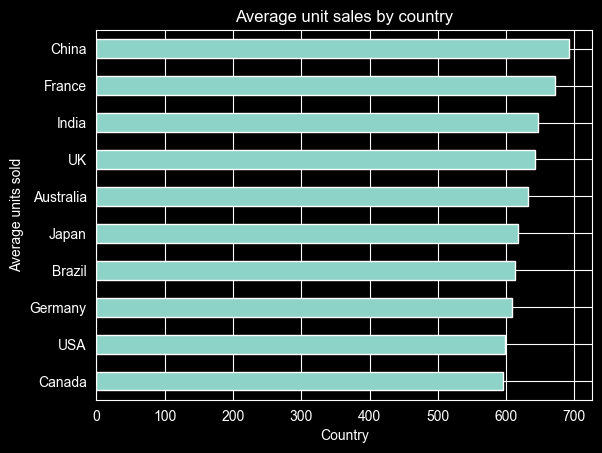

In [6]:
plt.figure()
df.groupby("country")["units_sold"].mean().sort_values().plot(kind="barh")
plt.title("Average unit sales by country")
plt.xlabel("Country")
plt.ylabel("Average units sold")
plt.show()

China is the leading country in average sales

##### Market share by engine type

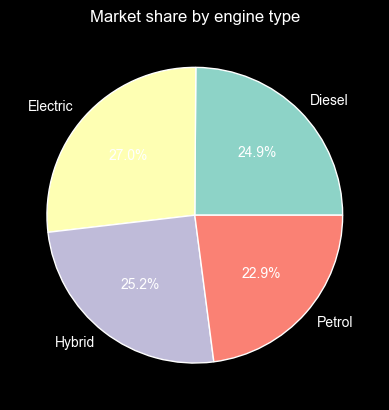

In [9]:
plt.figure()
sales_by_engine = df.groupby("engine_type")["units_sold"].sum()
plt.pie(sales_by_engine.values, labels=sales_by_engine.index, autopct='%1.1f%%')
plt.title("Market share by engine type")
plt.show()

Vehicles with an electric drivetrain have most of the market shar, while petrol has the least. But there is not a large difference between all 4 engine types.

##### Average Sales trend with time

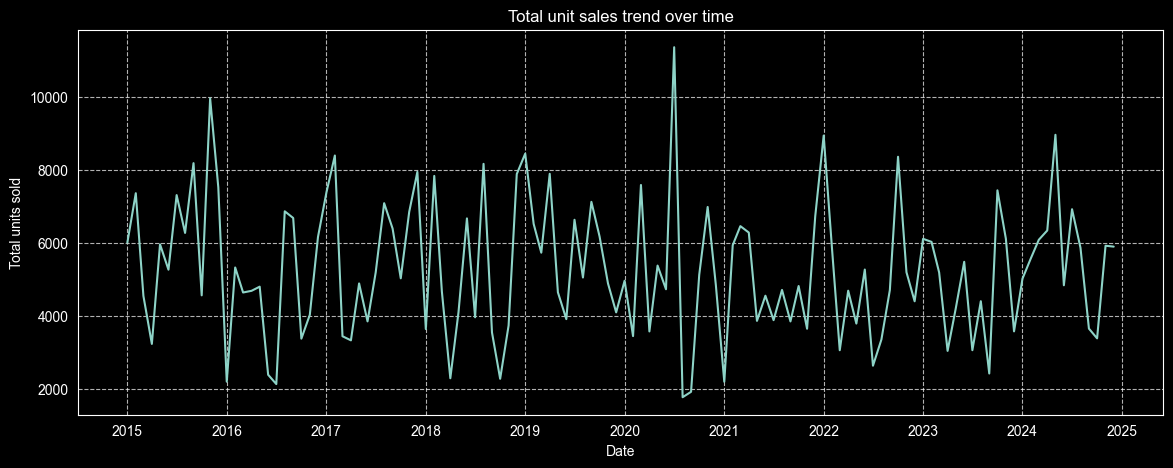

In [8]:
time_series_data = df.groupby(['year', 'month'])['units_sold'].sum().reset_index()
time_series_data['date'] = pd.to_datetime(time_series_data[['year', 'month']].assign(DAY=1))
time_series_data = time_series_data.sort_values('date')

plt.figure(figsize=[14, 5])
sns.lineplot(data=time_series_data, x="date", y="units_sold")
plt.title("Total unit sales trend over time")
plt.xlabel("Date")
plt.ylabel("Total units sold")
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()

The highest sales was in mid 2020, and the lowest (drop) followed it. This may be due to the global lockdown during the COVID outbreak in 2020.